# Finding Twitter communities with Label Propagation — and tuning it properly
**Can we group Twitter users into communities that share interests, using only who-follows-whom and which #hashtags / @mentions they use?**

This notebook walks through the whole process, from raw data to a tuned, honestly-tested model. You can run it top to bottom on Colab (*Runtime → Run all*).

| Step | Question it answers |
|---|---|
| 1 · Setup | Get the code and the SNAP *ego-Twitter* data |
| 2 · Data | What does the data look like? |
| 3 · LPA | How does Label Propagation actually work? |
| 4 · Graphs | How do we turn follows + interests into one graph? |
| 5 · Split | How do we keep a fair, untouched test set? |
| 6 · Tuning | Which graph settings give the best communities? |
| 7 · Final test | Does the tuned model really beat the default? |
| 8 · Why it works | Which settings matter? Is it stable? |
| 9 · Picture | What do the communities look like? |

> **How to read this notebook.** Every section starts with a short *what / why* note and ends with a **Takeaway** line. If you only have two minutes, read the Takeaways.

### Key terms
| Term | Plain meaning |
|---|---|
| **Ego network** | One Twitter user (the *ego*) plus the accounts they follow and the follow links among those accounts. The dataset has 973. |
| **Circle** | A list the ego made by hand (like a Twitter List). We use circles as a *weak* ground truth. |
| **Token** | One interest: a `#hashtag` or `@mention` a user has written. |
| **LPA** | *Label Propagation Algorithm.* Everyone starts with their own label, then repeatedly copies the most common label among their neighbours. Users who end up with the same label form a community. |
| **TF-IDF** | A weighting that makes rare, specific tokens (`#esports`) count more than common ones (`#ff`). |
| **Interest purity** | In each community, the share of users who use the community's most common token. Higher = members share a topic. **Our main goal.** |
| **Follow modularity** | How much denser *follow links* are inside communities than chance. Higher = communities respect the social structure. |
| **Largest share** | Share of users in the biggest community. Near 1.0 means LPA collapsed everyone into one blob (useless). |
| **Coverage** | Share of users placed in a community of 2+ people (not left alone). |
| **Circle F1 / Omega** | Agreement with the hand-made circles (best-match F1, and the overlap-aware Omega index). |

## 1 · Setup
This cell clones the project code from GitHub (the same `backend/` and `pipeline/` code that produced the project's results), installs a few libraries, and downloads + cleans the SNAP data (~2 minutes the first time).

**Choose how heavy the run is** with `MODE`:
* `"quick"` – about 15 tuning trials on a small sample of egos. About 10 minutes on a laptop (Colab may be slower). Good for a demo; numbers will be close to, but not identical to, the full run.
* `"full"` – the project's real settings (60 trials, 100 train egos, every validation and test ego). Much slower (an hour or more).

In [1]:
MODE = "quick"          # "quick" (demo, minutes)  or  "full" (replicates the project, slower)

REPO_URL = "https://github.com/JiyaSehgal04/Community-Detection-Among-Social-Media-Users-using-lpa.git"
BRANCH   = "jiya-analysis"                      # branch that contains the tuning code
SUBDIR   = "Label_Propogation_Twitter"

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def sh(cmd):
    print("$", cmd); subprocess.run(cmd, shell=True, check=True)

if not os.path.exists("backend"):
    if os.path.exists("../backend"):            # running from the repo's notebooks/ folder
        os.chdir("..")
    else:                                        # Colab / fresh machine
        if not os.path.exists("lpa_repo"):
            sh(f"git clone --depth 1 --branch {BRANCH} {REPO_URL} lpa_repo")
        os.chdir(os.path.join("lpa_repo", SUBDIR))
sys.path.insert(0, os.getcwd())
print("working in", os.getcwd())

if IN_COLAB:
    sh("pip install -q networkx scikit-learn scipy pandas pyarrow matplotlib")

if not os.path.exists("data/processed/users.parquet"):
    sh(f"{sys.executable} -m pipeline.download")      # SNAP files (~350 MB unpacked)
    sh(f"{sys.executable} -m pipeline.preprocess")    # -> 6 clean tables in data/processed/

working in /Users/jiyasehgal/Developer/Label_Propogation_Algorithm/Label_Propogation_Twitter


In [2]:
import json, random, time, itertools, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

from backend import graphs, lpa, metrics as m
from pipeline import tune, split as split_mod, analyze

warnings.filterwarnings("ignore", category=UserWarning)

# ---- run size ------------------------------------------------------------------------
PRESETS = {
    "quick": dict(n_trials=15, top_n=3, n_train=30, n_val=30, n_test=40),
    "full":  dict(n_trials=60, top_n=5, n_train=100, n_val=None, n_test=None),   # None = use all
}
CFG = PRESETS[MODE]
SEED = 42
OUT = Path("outputs/colab"); (OUT / "figures").mkdir(parents=True, exist_ok=True)

# ---- one consistent look for every chart ---------------------------------------------
BLUE, ORANGE, GREEN, RED = "#2a78d6", "#eb6834", "#2f9e6e", "#c9453f"
INK, INK2, GRIDC, SOFT = "#16181d", "#5b6068", "#e6e8ec", "#f3f4f6"
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#8c564b"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRIDC,
    "grid.linewidth": 0.7, "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
})

def headline(fig, title, sub=None, y=None):
    # Big title = the finding; small grey line = what is plotted. Offsets are in inches so they work at any figure height.
    h = fig.get_size_inches()[1]
    fig.suptitle(title, x=0.01, y=1 + (0.46 if sub else 0.2) / h, ha="left", va="bottom", fontsize=14, fontweight="bold", color=INK)
    if sub: fig.text(0.01, 1 + 0.14 / h, sub, ha="left", va="bottom", fontsize=9.5, color=INK2)

def save(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", bbox_inches="tight"); plt.show()

print(f"MODE = {MODE!r}  ->  {CFG}")

MODE = 'quick'  ->  {'n_trials': 15, 'top_n': 3, 'n_train': 30, 'n_val': 30, 'n_test': 40}


## 2 · The data
We load six clean tables (made by `pipeline.preprocess`). Every ego network is a small, separate world: *who follows whom* among ~100–900 accounts, what each account tweets about, and the ego's hand-made circles.

973 ego networks (938 have circles) · 81,306 users · 1,084,064 (user, token) pairs


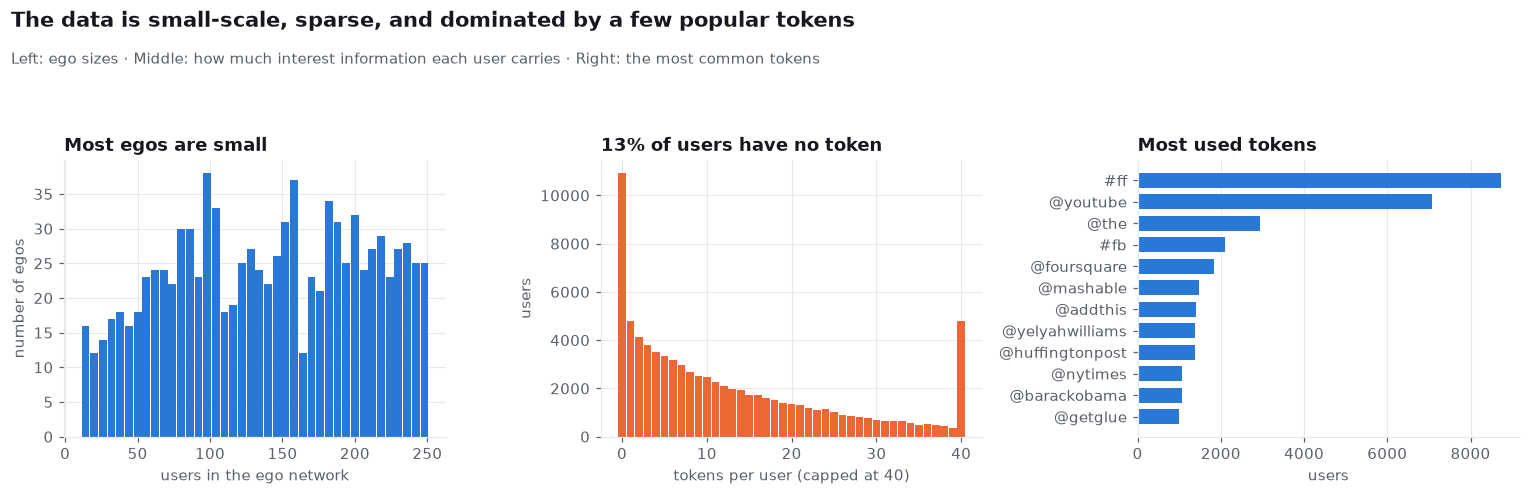

In [3]:
data = graphs.Dataset.load("data/processed")
n_tok = data.interests.groupby("user_id").size().reindex(data.users.user_id, fill_value=0)
with_c = data.egos[data.egos.has_circles]

print(f"{len(data.egos)} ego networks ({len(with_c)} have circles) · "
      f"{len(data.users):,} users · {len(data.interests):,} (user, token) pairs")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(data.egos.n_nodes, bins=40, color=BLUE, rwidth=0.9)
ax[0].set(xlabel="users in the ego network", ylabel="number of egos"); ax[0].set_title("Most egos are small")
ax[1].hist(n_tok.clip(upper=40), bins=np.arange(0, 42) - 0.5, color=ORANGE, rwidth=0.9)
ax[1].set(xlabel="tokens per user (capped at 40)", ylabel="users")
ax[1].set_title(f"{(n_tok == 0).mean():.0%} of users have no token")
top = data.interests.token.value_counts().head(12)[::-1]
ax[2].barh(top.index, top.values, color=BLUE, height=0.7); ax[2].grid(axis="y", visible=False)
ax[2].set(xlabel="users"); ax[2].set_title("Most used tokens")
headline(fig, "The data is small-scale, sparse, and dominated by a few popular tokens",
         "Left: ego sizes · Middle: how much interest information each user carries · Right: the most common tokens")
plt.tight_layout(); save(fig, "01_data")

**Takeaway.** Many users carry few or no tokens, and a handful of tokens (`#ff`, big-brand `@mentions`) are used by lots of people. If we do nothing about that, popular tokens will glue unrelated users together — one reason the tuning later turns on *outlier rules*.

## 3 · Label Propagation, step by step
**The algorithm** (Raghavan et al., 2007; weighted, asynchronous, implemented from scratch in `backend/lpa.py`):
1. Give every node its own label.
2. Visit nodes in random order. Each node adopts the label with the **largest total edge weight** among its neighbours (ties broken randomly).
3. Repeat until no label changes.

Below, a toy graph of three friend groups with a few cross-links. Colours are labels. Watch the dozens of tiny colour islands merge into three groups.

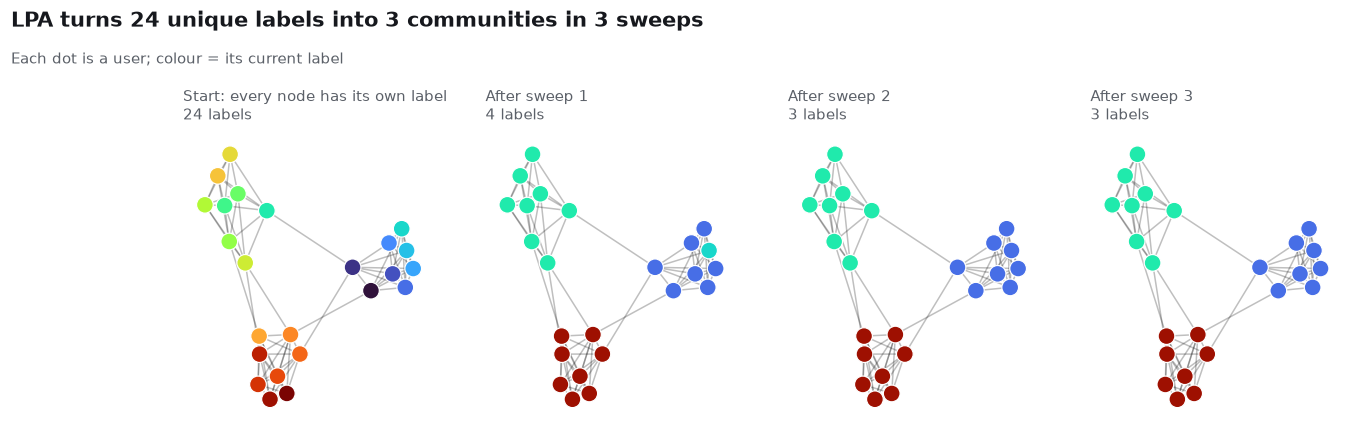

In [4]:
toy = nx.relaxed_caveman_graph(3, 8, 0.08, seed=7)
for a, b in toy.edges: toy[a][b]["weight"] = 1.0
res = lpa.label_propagation(toy, seed=3, trace=True)
pos = nx.spring_layout(toy, seed=4, k=0.55)

n_label = len({l for s in res.trace for l in s.values()})
cmap = plt.cm.turbo
colors = {l: cmap(i / max(n_label - 1, 1)) for i, l in enumerate(sorted({l for s in res.trace for l in s.values()}))}
shown = sorted({0, 1, min(2, len(res.trace) - 1), len(res.trace) - 1})
fig, axes = plt.subplots(1, len(shown), figsize=(3.4 * len(shown), 3.5))
for ax, t in zip(np.atleast_1d(axes), shown):
    snap = res.trace[t]; ax.axis("off")
    nx.draw_networkx_edges(toy, pos, ax=ax, alpha=0.25, width=1)
    nx.draw_networkx_nodes(toy, pos, ax=ax, node_size=120, linewidths=0.8, edgecolors="white",
                           node_color=[colors[snap[n]] for n in toy])
    ax.set_title(("Start: every node has its own label" if t == 0 else f"After sweep {t}") +
                 f"\n{len(set(snap.values()))} labels", fontsize=10, color=INK2, fontweight="normal")
headline(fig, f"LPA turns {toy.number_of_nodes()} unique labels into {len(set(res.labels.values()))} communities in {res.iterations} sweeps",
         "Each dot is a user; colour = its current label")
save(fig, "02_lpa_steps")

**Takeaway.** LPA needs no "number of communities" up front, only looks at neighbours (so it's fast), and stops by itself. Its weakness: on a *dense* graph it can let one label swallow everything — we'll see this with the default settings.

## 4 · Turning follows and interests into one graph
LPA needs a weighted graph. We can build three:

* **Follow graph** – an edge if one user follows the other (optionally only if *mutual*). Pure social structure.
* **Interest graph** – connect each user to their **k** most similar users (TF-IDF cosine similarity ≥ **min_sim**). Pure shared interests.
* **Hybrid graph** (what we tune) – interest edges **plus** follow edges, where a follow edge is worth `follow_weight` of an interest edge.

Same ego, same algorithm, three graphs:

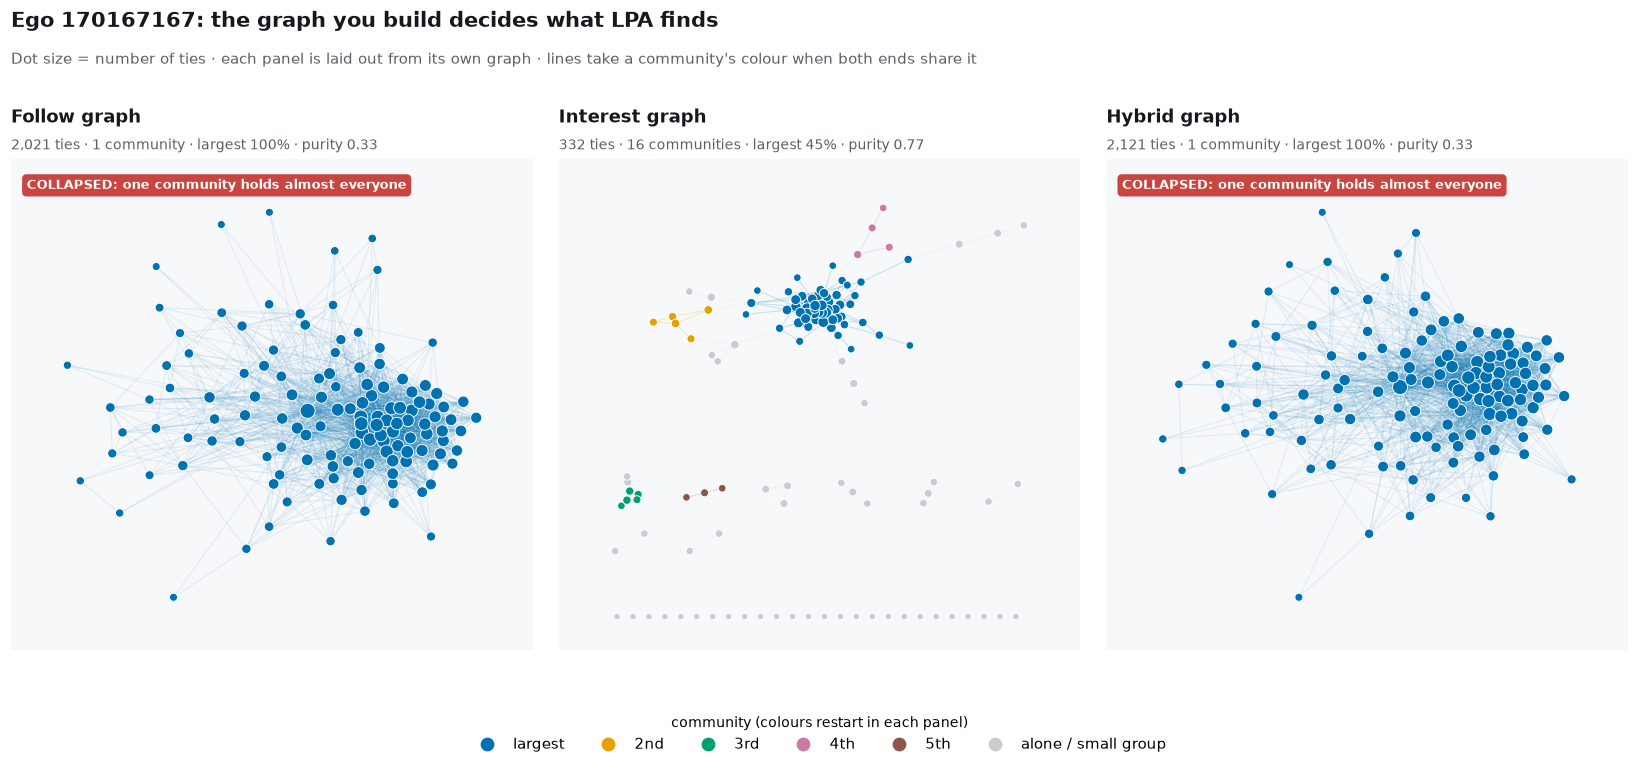

In [5]:
# pick a train ego of moderate size so the picture is readable
all_split_path = Path("data/processed/split.json")
if not all_split_path.exists():
    split_mod.save_split(split_mod.make_split(data.egos, seed=SEED), all_split_path, SEED)
split = split_mod.load_split(all_split_path)

cands = data.egos[data.egos.ego_id.isin(split["train"])].assign(d=lambda d: (d.n_nodes - 130).abs())
demo_ego = int(cands.sort_values("d").ego_id.iloc[0])
tokens_both = data.user_tokens("both")
dflt = tune.DEFAULT_CONFIG

# ---- drawing helpers (also reused for the tuned-vs-default picture in section 9) ---------------------
COMM_COLORS = [OKABE[i] for i in (0, 1, 2, 3, 7)]     # blue, orange, green, pink, brown: five colour-blind-safe hues
COMM_RANKS = ["largest", "2nd", "3rd", "4th", "5th"]  # what each colour means, in order
ALONE = "#c9ccd1"                                      # grey = alone, or in a group too small to colour

def layout_panel(G, seed=1):
    """Lay a graph out like a map: the biggest connected group in the middle (from its own ties), smaller groups as
    small islands on shelves beneath it, and users with no tie at all in tidy rows at the bottom."""
    groups = sorted(nx.connected_components(G), key=len, reverse=True)
    linked = [g for g in groups if len(g) > 1]
    loners = [n for g in groups if len(g) == 1 for n in g]
    if not linked:
        return {n: (i, 0) for i, n in enumerate(loners)}
    pos = {n: tuple(xy) for n, xy in nx.spring_layout(G.subgraph(linked[0]), seed=seed, weight="weight", iterations=200).items()}
    y, per_row = -1.5, 6                                    # the main group spans about -1..1, shelves start below it
    for i, group in enumerate(linked[1:]):
        row, col = divmod(i, per_row)
        centre = ((col - (per_row - 1) / 2) * 0.36, y - 0.4 * row)
        scale = min(0.16, 0.05 * len(group) ** 0.5)
        for n, (dx, dy) in nx.spring_layout(G.subgraph(group), seed=seed, scale=scale).items():
            pos[n] = (centre[0] + dx, centre[1] + dy)
    y -= 0.4 * (len(linked[1:]) // per_row + 1) + 0.2
    for i, n in enumerate(loners):                          # rows of up to 26 loners
        row, col = divmod(i, 26)
        pos[n] = (-1 + 2 * (col + 0.5) / min(26, len(loners)), y - 0.12 * row)
    return pos

def draw_partition(ax, G, comms, pos, title):
    """One panel. Dot size = number of ties; the five largest communities are coloured, everyone else is grey;
    a line takes its community's colour when both ends belong to it. `title` = 'heading\\nstats line'."""
    coloured_comms = [c for c in comms if len(c) > 1][:5]
    colour_of = {n: COMM_COLORS[i] for i, c in enumerate(coloured_comms) for n in c}

    same, other = [], []                                # ties inside one coloured community vs everything else
    for u, v in G.edges:
        (same if u in colour_of and colour_of[u] == colour_of.get(v) else other).append((u, v))
    alpha = float(np.clip(40 / max(G.number_of_edges(), 1), 0.06, 0.5))       # denser graph -> fainter lines
    if other:
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=other, edge_color="#b8bcc4", alpha=alpha, width=0.5)
    if same:
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=same, edge_color=[colour_of[u] for u, _ in same],
                               alpha=min(alpha * 1.6, 0.6), width=0.7)

    deg = dict(G.degree)
    for nodes in ([n for n in G if n not in colour_of], [n for n in G if n in colour_of]):    # grey first, colour on top
        if nodes:
            nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax, node_size=[18 + 7 * deg[n] ** 0.5 for n in nodes],
                                   node_color=[colour_of.get(n, ALONE) for n in nodes], linewidths=0.6, edgecolors="white")

    header, _, stats = title.partition("\n")
    collapsed = bool(comms) and max(len(c) for c in comms) / G.number_of_nodes() > 0.7     # one community swallowed almost everyone
    ax.set_title(header, loc="left", fontsize=12, fontweight="bold", color=INK, pad=24)
    ax.text(0, 1.02, stats, transform=ax.transAxes, fontsize=9, color=INK2)
    if collapsed:                                           # a small red tag, so the warning cannot collide with the text
        ax.text(0.03, 0.96, "COLLAPSED: one community holds almost everyone", transform=ax.transAxes, fontsize=8.5,
                color="white", fontweight="bold", va="top",
                bbox=dict(boxstyle="round,pad=0.35", facecolor=RED, edgecolor="none"))
    ax.set_facecolor("#f7f8fa"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.margins(0.08)
    for side in ax.spines.values():
        side.set_visible(False)

modes = {"Follow graph": "follow", "Interest graph": "interest", "Hybrid graph": "hybrid"}
graphs_demo = {k: graphs.build_graph(data, demo_ego, v, direction="any", k=10, min_sim=0.2, tokens="both", follow_weight=0.3)
               for k, v in modes.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.8), gridspec_kw=dict(wspace=0.05, left=0.01, right=0.99))
for ax, (name, G) in zip(axes, graphs_demo.items()):
    comms = lpa.best_of_runs(G, runs=10, seed=SEED)[0].communities
    stats = m.community_stats(comms)
    purity = m.interest_purity(comms, tokens_both)
    draw_partition(ax, G, comms, layout_panel(G),
                   f"{name}\n{G.number_of_edges():,} ties · {stats['n_communities']} {'community' if stats['n_communities'] == 1 else 'communities'} · "
                   f"largest {stats['largest_share']:.0%} · purity {purity:.2f}")
fig.legend(handles=[Line2D([], [], marker="o", ls="", markersize=8, color=c, label=r) for c, r in zip(COMM_COLORS, COMM_RANKS)]
                   + [Line2D([], [], marker="o", ls="", markersize=8, color=ALONE, label="alone / small group")],
           title="community (colours restart in each panel)", title_fontsize=9, loc="lower center", ncol=6,
           bbox_to_anchor=(0.5, -0.07), fontsize=9.5)
headline(fig, f"Ego {demo_ego}: the graph you build decides what LPA finds",
         "Dot size = number of ties · each panel is laid out from its own graph · lines take a community's colour when both ends share it")
save(fig, "03_graph_modes")

**Takeaway.** The graph you feed LPA decides what "community" means. Dense follow edges tend to pull everyone into one blob (see how the follow and default-hybrid panels can collapse), while the interest graph separates topics but leaves some users alone. The hybrid graph is meant to balance the two — but it has **8 settings** (k, min_sim, follow_weight, mutual-vs-any follows, hashtag/mention/both, and three outlier rules). Picking them by hand is guesswork. That is what tuning is for.

## 5 · A fair split: train / validation / test egos
If we tuned and scored on the same networks we would just reward settings that fit those networks. So we split the **egos** (not users) into three groups, stratified by network size so every group has big and small networks:

| Group | Used for |
|---|---|
| **train** (60%) | try many configurations and rank them |
| **validation** (20%) | re-rank the best finalists on networks they have never seen — this picks the winner |
| **test** (20%) | **scored once, at the very end.** Code in `pipeline/` refuses to tune on these (`assert_no_test_egos`). |

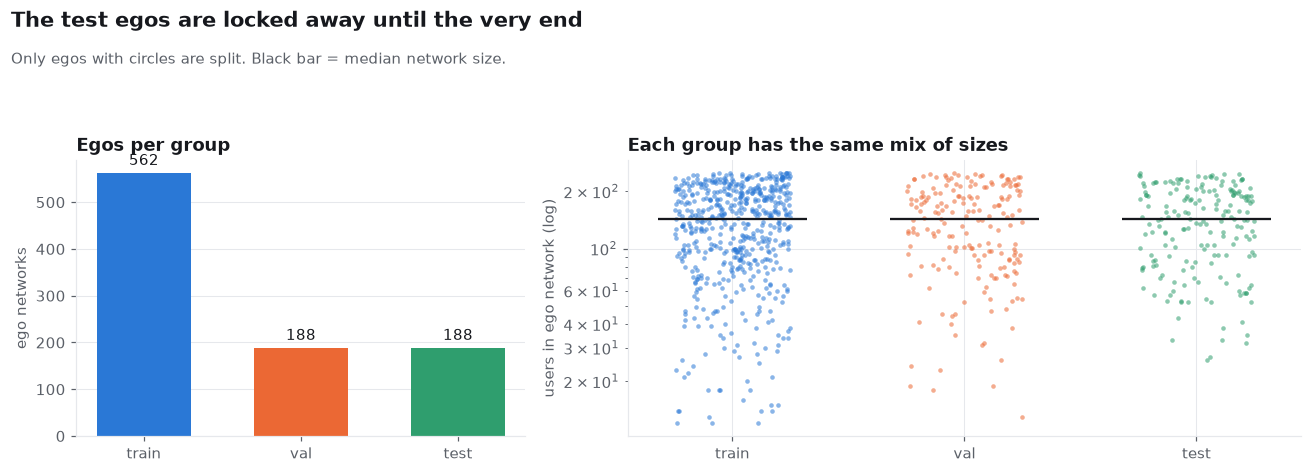

In [6]:
sizes = data.egos.set_index("ego_id").n_nodes
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[1, 1.5]))
counts = {k: len(split[k]) for k in ("train", "val", "test")}
bars = ax[0].bar(counts.keys(), counts.values(), color=[BLUE, ORANGE, GREEN], width=0.6)
ax[0].bar_label(bars, padding=3, color=INK); ax[0].grid(axis="x", visible=False)
ax[0].set(ylabel="ego networks"); ax[0].set_title("Egos per group")
for i, k in enumerate(("train", "val", "test")):
    s = sizes.loc[split[k]]
    ax[1].scatter(np.full(len(s), i) + np.random.default_rng(0).uniform(-0.25, 0.25, len(s)), s, s=9,
                  alpha=0.55, color=[BLUE, ORANGE, GREEN][i], linewidths=0)
    ax[1].hlines(s.median(), i - 0.32, i + 0.32, color=INK, lw=1.5)
ax[1].set_xticks(range(3), ["train", "val", "test"]); ax[1].set_yscale("log")
ax[1].set(ylabel="users in ego network (log)"); ax[1].set_title("Each group has the same mix of sizes")
headline(fig, "The test egos are locked away until the very end", "Only egos with circles are split. Black bar = median network size.")
plt.tight_layout(); save(fig, "04_split")

**Takeaway.** Because the test egos never influence any choice, the final test score is an honest estimate of how the tuned model behaves on *new* networks.

## 6 · Tuning (this is the "training")
LPA has no weights to learn, so "training" means **searching for the best graph settings**. The recipe (`pipeline/tune.py`):

1. **Random search.** Draw configurations from a grid of 8 settings (trial 0 is always the default config, as a reference). Build each config's graph on every **train** ego, run LPA 10 times (keep the best-modularity run), and average the metrics.
2. **Objective** = `interest purity + follow modularity` (shared interests *and* social structure).
3. **Guardrails.** A config is only *feasible* if its largest community holds ≤ 50% of users and ≥ 80% of users are in a community of 2+. This stops "everyone in one blob" from winning.
4. **Re-rank on validation.** The top finalists are re-scored on **validation** egos; the best one there is the winner.

Search space:

In [7]:
print(pd.Series({k: v for k, v in tune.GRID.items()}).to_frame("choices").to_string())
n_combos = int(np.prod([len(v) for v in tune.GRID.values()]))
print(f"\n{n_combos:,} possible combinations — we sample {CFG['n_trials']} of them.")

                                         choices
k                            [5, 10, 15, 20, 30]
min_sim               [0.1, 0.15, 0.2, 0.3, 0.4]
follow_weight    [0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
direction                          [any, mutual]
tokens                  [hashtag, mention, both]
token_max_share         [None, 0.01, 0.02, 0.05]
hub_cap                       [None, 10, 25, 50]
max_tokens                    [None, 10, 20, 50]

57,600 possible combinations — we sample 15 of them.


In [8]:
rng = random.Random(SEED)
train_egos = sorted(rng.sample(split["train"], min(CFG["n_train"] or 10**9, len(split["train"]))))
val_egos   = sorted(rng.sample(split["val"],   min(CFG["n_val"]   or 10**9, len(split["val"]))))

t0 = time.time()
trials, best_cfg = tune.run_tuning(data, split, train_egos, val_egos,
                                   n_trials=CFG["n_trials"], top_n=CFG["top_n"], seed=SEED)
print(f"searched {CFG['n_trials']} configs on {len(train_egos)} train egos, "
      f"re-ranked top {CFG['top_n']} on {len(val_egos)} val egos in {(time.time()-t0)/60:.1f} min")
trials.to_csv(OUT / "trials.csv", index=False)
train_t = trials[trials.stage == "train"].copy()
val_t   = trials[trials.stage == "val"].copy()
best_trial = int(val_t.trial.iloc[0])
print("\nBEST CONFIG:"); print(json.dumps(best_cfg, indent=2))

searched 15 configs on 30 train egos, re-ranked top 3 on 30 val egos in 0.9 min

BEST CONFIG:
{
  "k": 30,
  "min_sim": 0.2,
  "follow_weight": 0.1,
  "direction": "mutual",
  "tokens": "mention",
  "token_max_share": 0.05,
  "hub_cap": 10,
  "max_tokens": 20
}


### 6a · Every trial, on one map
Each dot is one configuration scored on the train egos. Good = high **purity** (up) without collapsing into one giant community (left of the red zone).

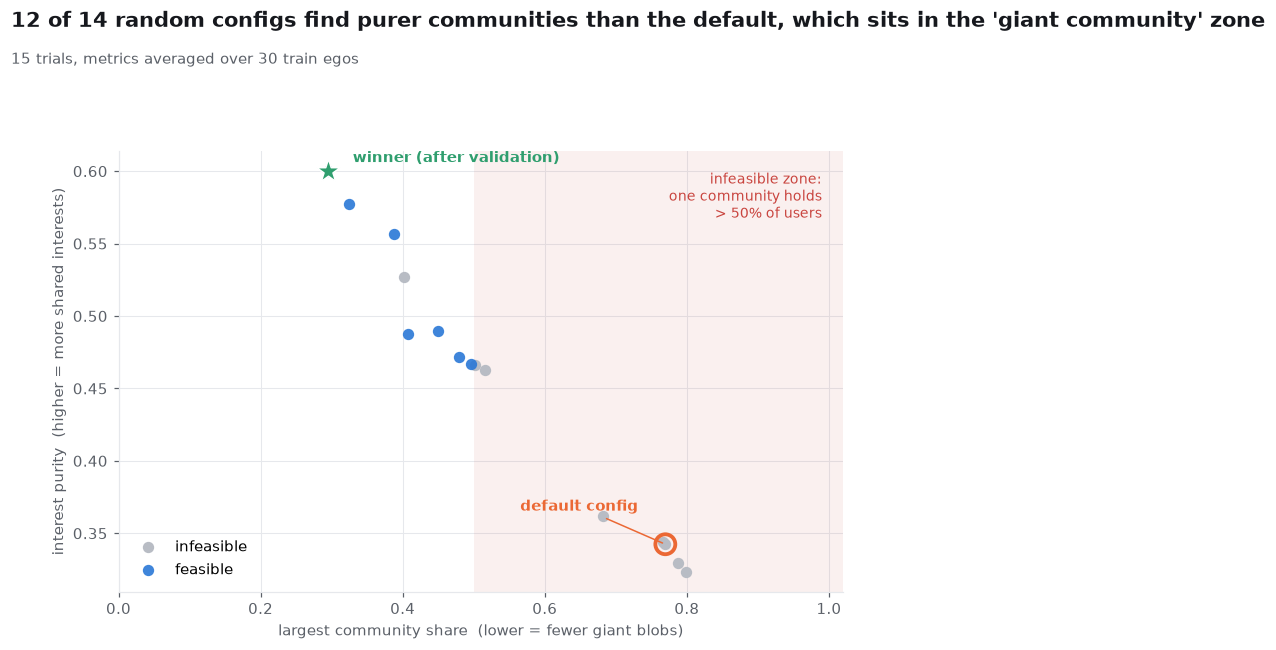

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.axvspan(tune.MAX_LARGEST_SHARE, 1.02, color=RED, alpha=0.08, lw=0)
ax.text(0.99, train_t.interest_purity.max(), "infeasible zone:\none community holds\n> 50% of users", ha="right", va="top", color=RED, fontsize=9)
feas = train_t.feasible.astype(bool)
ax.scatter(train_t.largest_share[~feas], train_t.interest_purity[~feas], s=55, color="#b8bcc4", label="infeasible", zorder=3, linewidths=0)
ax.scatter(train_t.largest_share[feas], train_t.interest_purity[feas], s=55, color=BLUE, label="feasible", zorder=3, linewidths=0, alpha=0.9)
d = train_t[train_t.trial == 0].iloc[0]
ax.scatter(d.largest_share, d.interest_purity, s=170, facecolor="none", edgecolor=ORANGE, lw=2.5, zorder=4)
ax.annotate("default config", (d.largest_share, d.interest_purity), xytext=(-95, 22), textcoords="offset points",
            color=ORANGE, fontweight="bold", arrowprops=dict(arrowstyle="-", color=ORANGE))
b = train_t[train_t.trial == best_trial]
if len(b):
    b = b.iloc[0]
    ax.scatter(b.largest_share, b.interest_purity, s=260, marker="*", color=GREEN, zorder=5, edgecolor="white")
    ax.annotate("winner (after validation)", (b.largest_share, b.interest_purity), xytext=(16, 6), textcoords="offset points",
                color=GREEN, fontweight="bold")
ax.set(xlabel="largest community share  (lower = fewer giant blobs)", ylabel="interest purity  (higher = more shared interests)",
       xlim=(0, 1.02))
ax.legend(loc="lower left")
n_better = int((train_t[train_t.trial != 0].interest_purity > d.interest_purity).sum())
headline(fig, f"{n_better} of {len(train_t) - 1} random configs find purer communities than the default, which sits in the 'giant community' zone",
         f"{CFG['n_trials']} trials, metrics averaged over {len(train_egos)} train egos")
save(fig, "05_trials_map")

### 6b · Leaderboard
The ten best trials on the train egos (best first). `feasible` must be `True` to be eligible.

In [10]:
cols = ["trial", "k", "min_sim", "follow_weight", "direction", "tokens", "token_max_share", "hub_cap", "max_tokens",
        "interest_purity", "follow_modularity", "largest_share", "coverage", "objective", "feasible"]
board = train_t[cols].head(10).reset_index(drop=True)
display(board.style.format({c: "{:.3f}" for c in ["interest_purity", "follow_modularity", "largest_share", "coverage", "objective"]},
                           na_rep="off")
        .background_gradient(subset=["objective"], cmap="Blues")
        .map(lambda v: "color:#2f9e6e;font-weight:bold" if v is True else ("color:#c9453f" if v is False else ""), subset=["feasible"])
        .hide(axis="index"))

trial,k,min_sim,follow_weight,direction,tokens,token_max_share,hub_cap,max_tokens,interest_purity,follow_modularity,largest_share,coverage,objective,feasible
12,30,0.200000,0.100000,mutual,mention,0.050000,10.000000,20.000000,0.600,0.095,0.295,0.838,0.695,True
10,30,0.150000,0.100000,mutual,mention,0.020000,10.000000,20.000000,0.578,0.100,0.325,0.849,0.677,True
11,5,0.150000,0.050000,mutual,mention,0.020000,off,10.000000,0.557,0.081,0.388,0.844,0.638,True
1,5,0.100000,1.000000,mutual,hashtag,0.010000,10.000000,off,0.488,0.105,0.408,0.834,0.593,True
13,10,0.150000,1.000000,mutual,both,0.050000,50.000000,20.000000,0.472,0.105,0.480,0.859,0.577,True
9,15,0.150000,0.200000,mutual,hashtag,0.020000,off,10.000000,0.490,0.076,0.450,0.827,0.566,True
8,10,0.200000,0.050000,any,hashtag,0.050000,25.000000,50.000000,0.467,0.077,0.496,0.952,0.544,True
7,5,0.400000,0.200000,mutual,both,0.010000,off,off,0.527,0.107,0.402,0.782,0.633,False
14,10,0.150000,0.500000,mutual,hashtag,off,off,10.000000,0.466,0.093,0.502,0.835,0.559,False
2,30,0.100000,0.500000,mutual,hashtag,off,off,10.000000,0.463,0.087,0.516,0.841,0.550,False


### 6c · Which settings matter?
For each setting, every dot is a trial; the bar is the average objective for that value. Settings where the bars differ a lot are the ones that drive quality. *(With only a few trials this is noisy — run `MODE="full"` for a steadier picture.)*

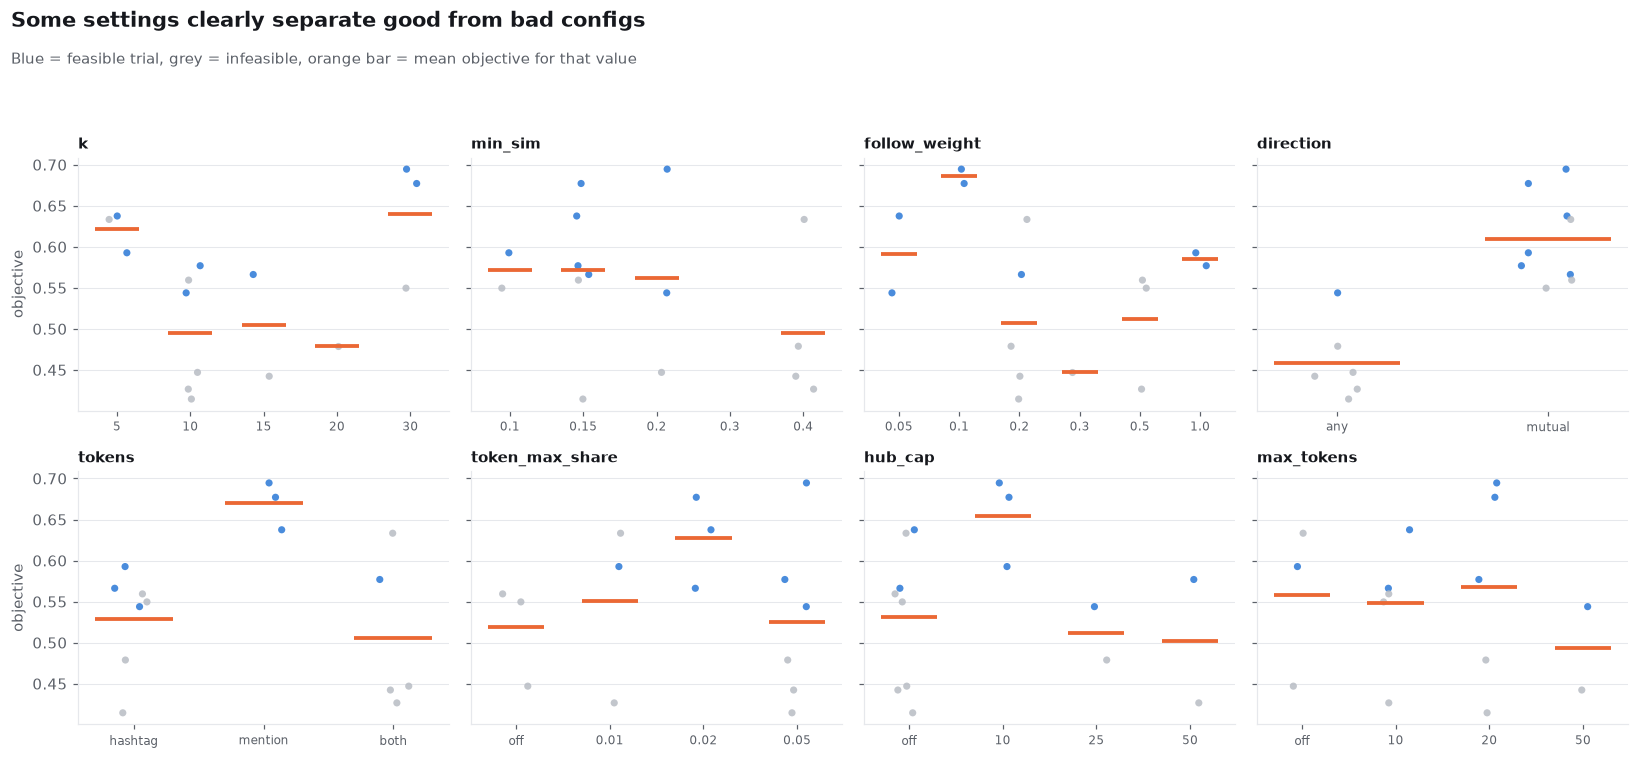

In [11]:
params = list(tune.GRID)
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
jit = np.random.default_rng(1)
for ax, p in zip(axes.ravel(), params):
    vals = [v for v in tune.GRID[p]]
    lab = ["off" if v is None else str(v) for v in vals]
    key = train_t[p].map(lambda v: "off" if pd.isna(v) else (str(int(v)) if p in ("k", "hub_cap", "max_tokens") else str(v)))
    for i, (v, l) in enumerate(zip(vals, lab)):
        l2 = l if not (p in ("k", "hub_cap", "max_tokens") and l != "off") else str(int(v))
        sel = train_t[key == l2]
        if len(sel):
            ax.scatter(np.full(len(sel), i) + jit.uniform(-0.15, 0.15, len(sel)), sel.objective, s=22,
                       color=np.where(sel.feasible.astype(bool), BLUE, "#b8bcc4"), alpha=0.85, linewidths=0, zorder=3)
            ax.hlines(sel.objective.mean(), i - 0.3, i + 0.3, color=ORANGE, lw=2.5, zorder=4)
    ax.set_xticks(range(len(vals)), lab, fontsize=8); ax.set_title(p, fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylabel("objective"); axes[1, 0].set_ylabel("objective")
headline(fig, "Some settings clearly separate good from bad configs", "Blue = feasible trial, grey = infeasible, orange bar = mean objective for that value")
plt.tight_layout(); save(fig, "06_param_effects")

### 6d · Validation: do the finalists hold up on networks they haven't seen?
Dumbbell = same configuration on **train** egos (hollow) vs **validation** egos (filled). A big drop would suggest the config over-fit its training egos.

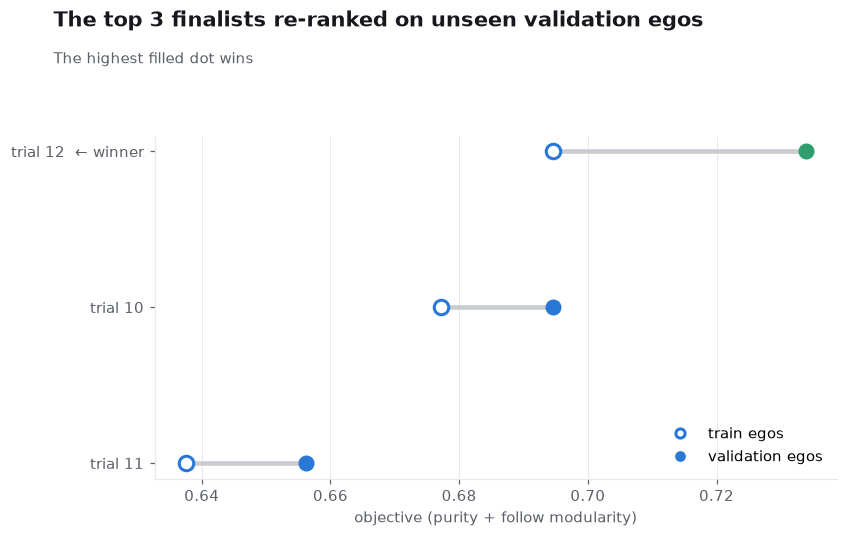

In [12]:
fin = val_t.merge(train_t[["trial", "objective"]], on="trial", suffixes=("_val", "_train")).sort_values("objective_val")
fig, ax = plt.subplots(figsize=(8, 0.75 * len(fin) + 1.8))
for i, r in enumerate(fin.itertuples()):
    ax.plot([r.objective_train, r.objective_val], [i, i], color="#c9ccd1", lw=3, zorder=1)
    ax.scatter(r.objective_train, i, s=90, facecolor="white", edgecolor=BLUE, lw=2, zorder=3)
    ax.scatter(r.objective_val, i, s=90, color=GREEN if r.trial == best_trial else BLUE, zorder=4)
ax.set_yticks(range(len(fin)), [f"trial {t}" + ("  ← winner" if t == best_trial else "") for t in fin.trial])
ax.set_xlabel("objective (purity + follow modularity)"); ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc="white", mec=BLUE, mew=2, label="train egos"),
                   Line2D([], [], marker="o", ls="", color=BLUE, label="validation egos")], loc="lower right")
headline(fig, f"The top {len(fin)} finalists re-ranked on unseen validation egos", "The highest filled dot wins")
save(fig, "07_validation")

**Takeaway.** Random search plus a validation re-rank gives us one frozen configuration. Nothing about it was chosen using the test egos.

## 7 · The final exam: tuned vs default vs Louvain on test egos
We freeze the winning config and score it **once** on the test egos, next to two references:
* **default** – the hand-picked starting config (k=10, min_sim=0.2, …)
* **Louvain on the tuned graph** – a different, well-known community algorithm on the *same* tuned graph (tests whether the *graph* or the *algorithm* matters)

Error bars are 95% bootstrap intervals (resampling egos).

In [13]:
test_egos = sorted(random.Random(0).sample(split["test"], min(CFG["n_test"] or 10**9, len(split["test"]))))
split_mod.assert_no_test_egos(train_egos + val_egos, split)           # the leak guard, shown explicitly
variants = {"tuned": (best_cfg, "lpa"), "default": (tune.DEFAULT_CONFIG, "lpa"),
            "louvain_on_tuned_graph": (best_cfg, "louvain")}
rows = []
for i, ego in enumerate(test_egos, 1):
    for name, (cfg, algo) in variants.items():
        rows.append({"ego_id": ego, "variant": name, **analyze.score_variant(data, cfg, ego, tokens_both, "hybrid", algo)})
    if i % 20 == 0: print(f"  scored {i}/{len(test_egos)} test egos")
test_df = pd.DataFrame(rows); test_df.to_csv(OUT / "test_scores.csv", index=False)
print(f"{len(test_egos)} test egos scored")

  scored 20/40 test egos
  scored 40/40 test egos
40 test egos scored


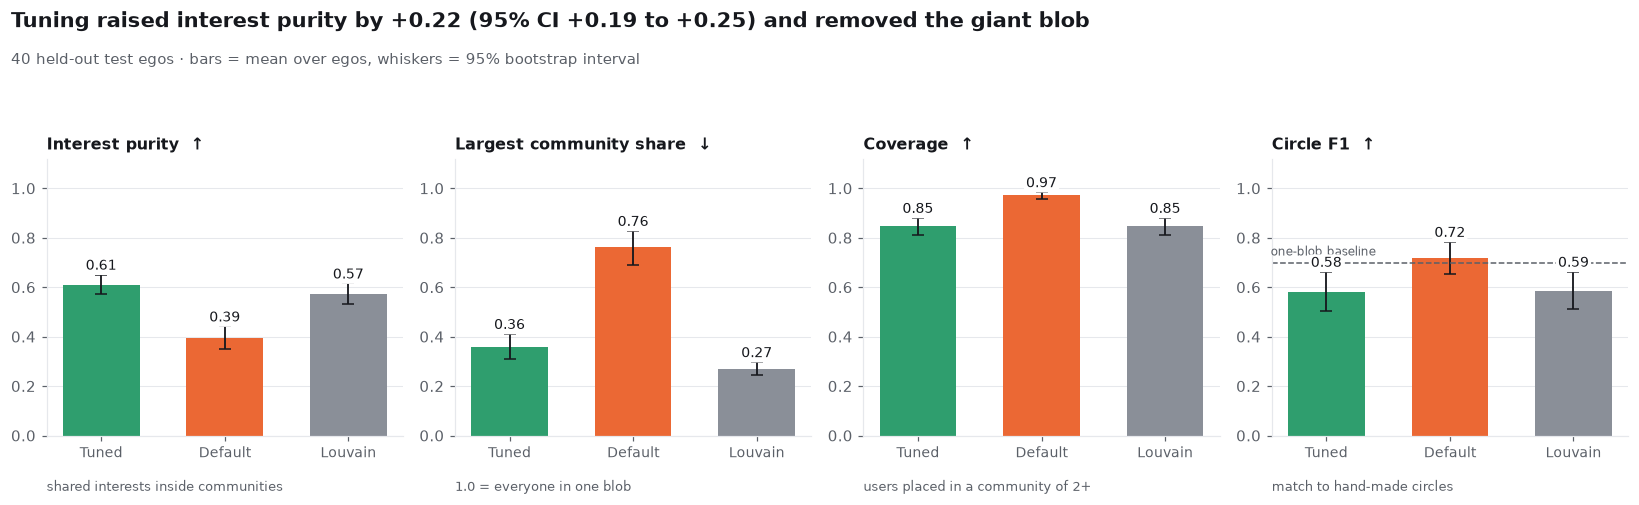

In [14]:
NAMES = {"tuned": "Tuned LPA", "default": "Default LPA", "louvain_on_tuned_graph": "Louvain (tuned graph)"}
COL   = {"tuned": GREEN, "default": ORANGE, "louvain_on_tuned_graph": "#8a8f98"}
panels = [("interest_purity", "Interest purity  ↑", "shared interests inside communities"),
          ("largest_share", "Largest community share  ↓", "1.0 = everyone in one blob"),
          ("coverage", "Coverage  ↑", "users placed in a community of 2+"),
          ("circle_f1", "Circle F1  ↑", "match to hand-made circles")]
wide = lambda col: test_df.pivot(index="ego_id", columns="variant", values=col)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (col, ttl, sub) in zip(axes, panels):
    w = wide(col)
    for i, v in enumerate(variants):
        bs = analyze.paired_bootstrap(w[v], np.zeros(len(w)))
        ax.bar(i, bs["mean"], color=COL[v], width=0.62, yerr=[[bs["mean"] - bs["lo"]], [bs["hi"] - bs["mean"]]],
               error_kw=dict(ecolor=INK, capsize=4, lw=1.2))
        ax.text(i, bs["hi"] + 0.02, f"{bs['mean']:.2f}", ha="center", color=INK, fontsize=9, zorder=6,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
    ax.set_xticks(range(3), ["Tuned", "Default", "Louvain"], fontsize=9); ax.grid(axis="x", visible=False)
    ax.set_title(ttl, fontsize=10.5); ax.set_ylim(0, 1.12)
    ax.text(0, -0.2, sub, transform=ax.transAxes, fontsize=8.5, color=INK2)
    if col == "circle_f1":
        base = test_df[test_df.variant == "tuned"].circle_f1_one_community.mean()
        ax.axhline(base, color=INK2, ls="--", lw=1); ax.text(-0.45, base + 0.03, "one-blob baseline", ha="left", fontsize=8, color=INK2)
pur = analyze.paired_bootstrap(wide("interest_purity")["tuned"], wide("interest_purity")["default"])
headline(fig, f"Tuning raised interest purity by {pur['mean']:+.2f} (95% CI {pur['lo']:+.2f} to {pur['hi']:+.2f}) and removed the giant blob",
         f"{len(test_egos)} held-out test egos · bars = mean over egos, whiskers = 95% bootstrap interval")
plt.tight_layout(); save(fig, "08_test_results")

> **Why does the default look better on Circle F1?** Circle F1 rewards large communities. If you put *everyone* in one community you already score the dashed "one-blob baseline". The default config does almost exactly that (look at its largest-share bar), so its F1 is inflated and tells us little. Interest purity and the guardrails are the fairer yardsticks here.

Per-ego view: does the tuned model win on *most* networks, or only on average?

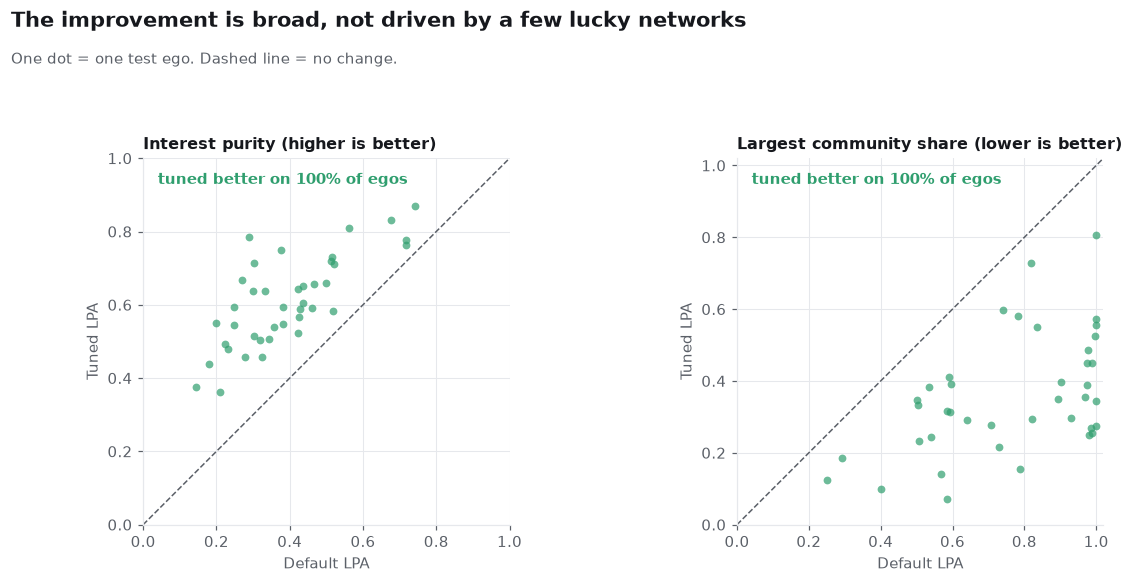

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, col, ttl, lim in ((axes[0], "interest_purity", "Interest purity (higher is better)", (0, 1)),
                          (axes[1], "largest_share", "Largest community share (lower is better)", (0, 1.02))):
    w = wide(col)
    ax.plot(lim, lim, color=INK2, lw=1, ls="--", zorder=1)
    ax.scatter(w["default"], w["tuned"], s=26, color=GREEN, alpha=0.7, linewidths=0, zorder=3)
    ax.set(xlabel=f"Default LPA", ylabel="Tuned LPA", xlim=lim, ylim=lim); ax.set_title(ttl, fontsize=10.5)
    better = (w["tuned"] > w["default"]).mean() if col == "interest_purity" else (w["tuned"] < w["default"]).mean()
    ax.text(0.04, 0.93, f"tuned better on {better:.0%} of egos", transform=ax.transAxes, color=GREEN, fontweight="bold")
    ax.set_aspect("equal")
headline(fig, "The improvement is broad, not driven by a few lucky networks", "One dot = one test ego. Dashed line = no change.")
plt.tight_layout(); save(fig, "09_per_ego")

**Takeaway.** On networks it never saw, the tuned config finds far more topic-pure communities and avoids the one-giant-community failure, while Louvain on the same graph is roughly comparable — meaning most of the gain comes from *building a better graph*, which is exactly what tuning controls.

## 8 · Why does the tuned config work?
Three checks (all on **validation** egos, never the test set, because they explain the model rather than judge it).

### 8a · Ablation – switch one ingredient back and see what breaks

  ablation: tuned (full)
  ablation: default
  ablation: follow-only graph
  ablation: interest-only graph
  ablation: without token_max_share
  ablation: without hub_cap
  ablation: without max_tokens
  ablation: k back to default
  ablation: follow_weight back to default
  ablation: direction back to default
  ablation: tokens back to default


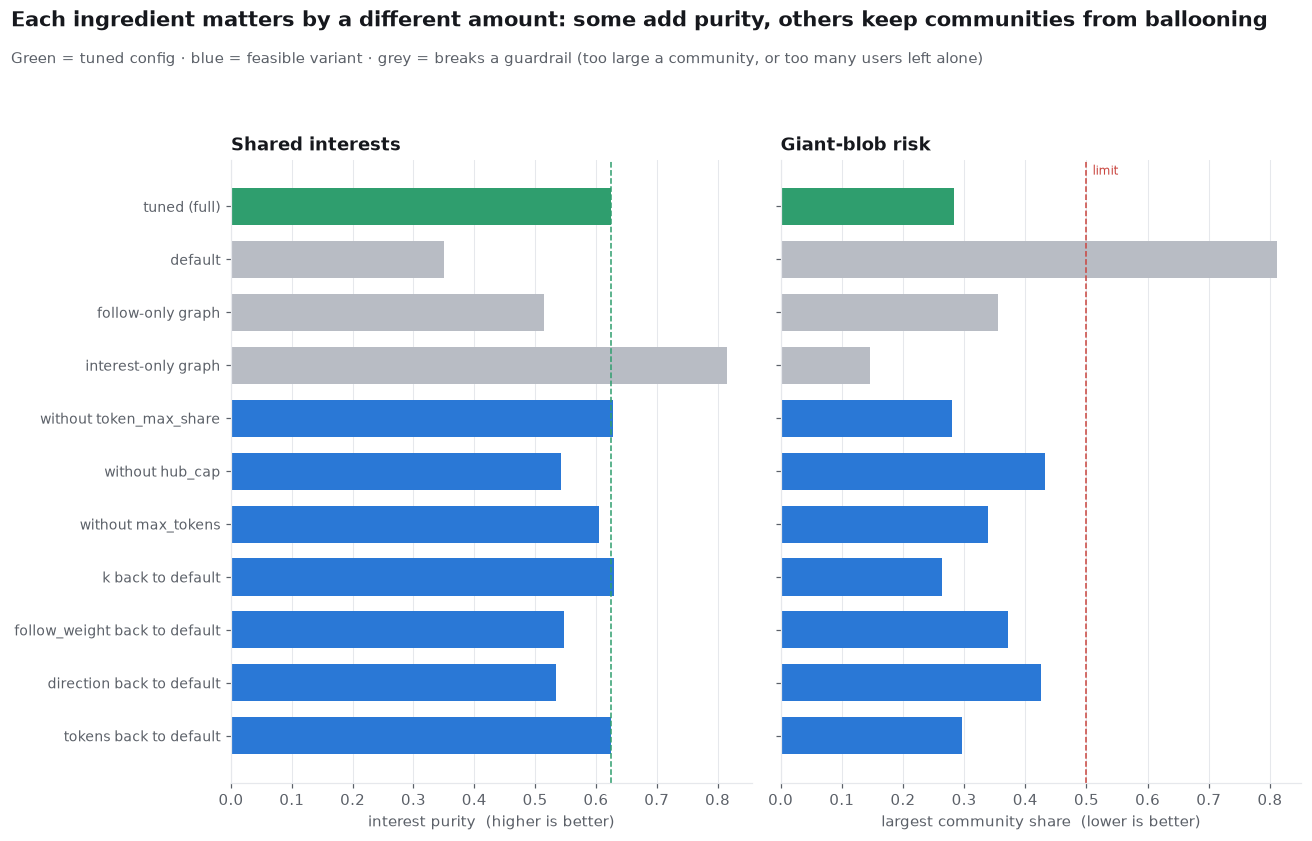

In [16]:
abl = analyze.run_ablation(data, split, val_egos, best_cfg)
abl.to_csv(OUT / "ablation.csv", index=False)
abl = abl.iloc[::-1].reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 0.45 * len(abl) + 2), sharey=True)
y = np.arange(len(abl))
full = abl[abl.variant == "tuned (full)"].iloc[0]
c1 = [GREEN if v == "tuned (full)" else (BLUE if f else "#b8bcc4") for v, f in zip(abl.variant, abl.feasible.astype(bool))]
axes[0].barh(y, abl.interest_purity, color=c1, height=0.7); axes[0].axvline(full.interest_purity, color=GREEN, ls="--", lw=1)
axes[0].set(xlabel="interest purity  (higher is better)"); axes[0].set_title("Shared interests")
axes[1].barh(y, abl.largest_share, color=c1, height=0.7); axes[1].axvline(tune.MAX_LARGEST_SHARE, color=RED, ls="--", lw=1)
axes[1].text(tune.MAX_LARGEST_SHARE + 0.01, len(abl) - 0.4, "limit", color=RED, fontsize=8)
axes[1].set(xlabel="largest community share  (lower is better)"); axes[1].set_title("Giant-blob risk")
axes[0].set_yticks(y, abl.variant, fontsize=9)
for ax in axes: ax.grid(axis="y", visible=False)
headline(fig, "Each ingredient matters by a different amount: some add purity, others keep communities from ballooning",
         "Green = tuned config · blue = feasible variant · grey = breaks a guardrail (too large a community, or too many users left alone)")
plt.tight_layout(); save(fig, "10_ablation")

> **Read the grey bars carefully.** The *interest-only graph* can score very high purity — but it fails a guardrail because it leaves many users alone in singleton communities. Purity by itself can be gamed; that is why the search also enforces coverage and a largest-share limit.

### 8b · Sensitivity – how fragile is the optimum?
Move one setting at a time (others fixed at the tuned values). A flat line means the choice barely matters; a steep one means it must be set carefully.

  sensitivity: k=5
  sensitivity: k=10
  sensitivity: k=15
  sensitivity: k=20
  sensitivity: k=30
  sensitivity: min_sim=0.1
  sensitivity: min_sim=0.15
  sensitivity: min_sim=0.2
  sensitivity: min_sim=0.3
  sensitivity: min_sim=0.4
  sensitivity: follow_weight=0.05
  sensitivity: follow_weight=0.1
  sensitivity: follow_weight=0.2
  sensitivity: follow_weight=0.3
  sensitivity: follow_weight=0.5
  sensitivity: follow_weight=1.0


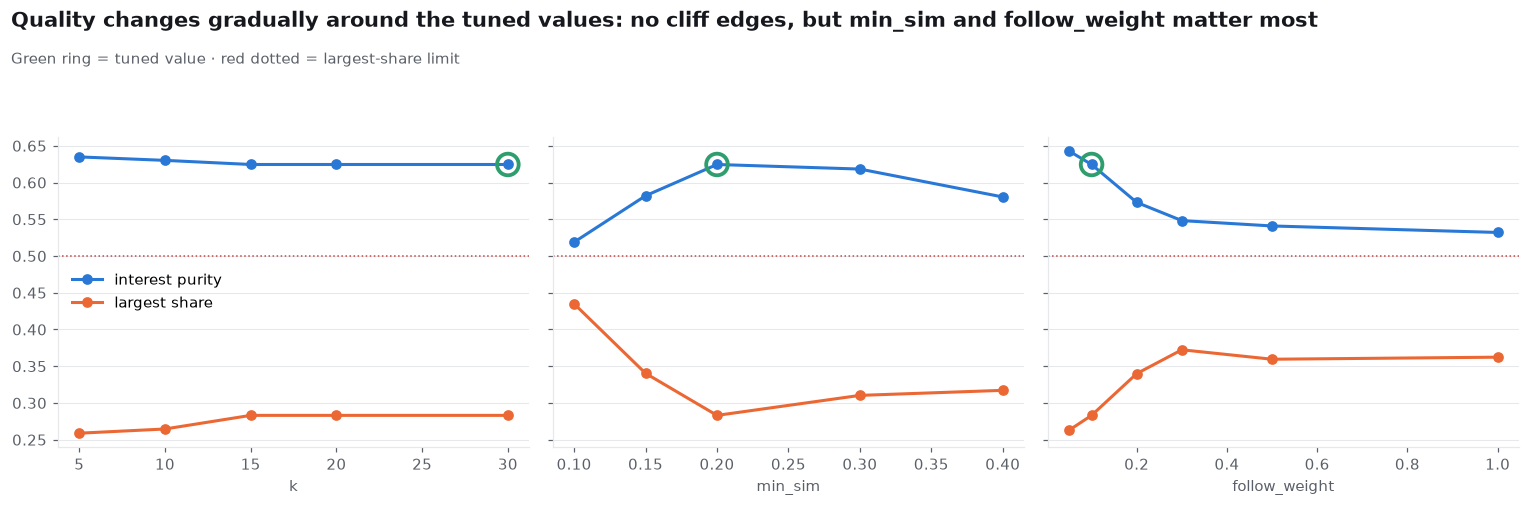

In [17]:
sens = analyze.run_sensitivity(data, split, val_egos, best_cfg)
sens.to_csv(OUT / "sensitivity.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, p in zip(axes, analyze.SWEEPS):
    s = sens[sens.param == p]
    ax.plot(s.value, s.interest_purity, "-o", color=BLUE, lw=2, label="interest purity")
    ax.plot(s.value, s.largest_share, "-o", color=ORANGE, lw=2, label="largest share")
    ax.axhline(tune.MAX_LARGEST_SHARE, color=RED, ls=":", lw=1)
    t = s[s.is_tuned]
    if len(t): ax.scatter(t.value, t.interest_purity, s=200, facecolor="none", edgecolor=GREEN, lw=2.5, zorder=5)
    ax.set_xlabel(p); ax.grid(axis="x", visible=False)
axes[0].legend(loc="center left")
headline(fig, "Quality changes gradually around the tuned values: no cliff edges, but min_sim and follow_weight matter most",
         "Green ring = tuned value · red dotted = largest-share limit")
plt.tight_layout(); save(fig, "11_sensitivity")

### 8c · Stability – LPA is random; do different seeds agree?
For each test ego we run LPA 10 times with different seeds and measure how similar the groupings are (ARI: 1 = identical, 0 = unrelated).

In [ ]:
cfg = best_cfg; ari_rows = []
for ego in test_egos:
    G = graphs.build_graph(data, ego, "hybrid", direction=cfg["direction"], k=cfg["k"], min_sim=cfg["min_sim"],
                           tokens=cfg["tokens"], follow_weight=cfg["follow_weight"], outliers=tune.outlier_config(cfg))
    if G.number_of_edges() == 0: continue
    nodes = sorted(G.nodes)
    vecs = [[lpa.label_propagation(G, seed=s).labels[n] for n in nodes] for s in analyze.STABILITY_SEEDS]
    ari_rows.append({"ego_id": ego, "mean_ari": float(np.mean([adjusted_rand_score(a, b) for a, b in itertools.combinations(vecs, 2)]))})
stab = pd.DataFrame(ari_rows); stab.to_csv(OUT / "stability.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(stab.mean_ari, bins=np.linspace(0, 1, 21), color=BLUE, rwidth=0.92)
ax.axvline(stab.mean_ari.median(), color=ORANGE, lw=2); ax.grid(axis="x", visible=False)
ax.text(stab.mean_ari.median() - 0.015, ax.get_ylim()[1] * 0.92, f"median {stab.mean_ari.median():.2f}", color=ORANGE, ha="right", fontweight="bold")
ax.set(xlabel="mean pairwise ARI between seeds", ylabel="test egos")
headline(fig, "Different random seeds usually find similar communities, but not identical ones",
         "That is why we run LPA 10 times and keep the highest-modularity run")
save(fig, "12_stability")

**Takeaway.** The gain is not a one-ingredient trick: several settings work together, results are not fragile around the optimum, and LPA's randomness is moderate and handled by best-of-10 runs.

## 9 · What the communities look like
One test ego, same layout, coloured by each configuration's partition. Colours = the 7 largest communities; grey = users who are alone or in tiny groups.

In [ ]:
sizes_t = data.egos[data.egos.ego_id.isin(test_egos)].assign(d=lambda d: (d.n_nodes - 200).abs())
show_ego = int(sizes_t.sort_values("d").ego_id.iloc[0])
Gt = graphs.build_graph(data, show_ego, "hybrid", direction=best_cfg["direction"], k=best_cfg["k"], min_sim=best_cfg["min_sim"],
                        tokens=best_cfg["tokens"], follow_weight=best_cfg["follow_weight"], outliers=tune.outlier_config(best_cfg))
Gd = graphs.build_graph(data, show_ego, "hybrid", direction="any", k=10, min_sim=0.2, tokens="both", follow_weight=0.3)
pos = nx.spring_layout(Gt, seed=2, weight="weight", k=0.3, iterations=100)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, (G, label) in zip(axes, ((Gd, "Default config"), (Gt, "Tuned config"))):
    comms = tune.communities_for(G, "lpa")
    st = m.community_stats(comms); pu = m.interest_purity(comms, tokens_both)
    draw_partition(ax, G, comms, {n: pos[n] for n in G}, f"{label}\n{st['n_communities']} communities · largest = {st['largest_share']:.0%} · purity = {pu:.2f}")
headline(fig, f"Ego {show_ego}: the default config lumps users together; the tuned config separates them into interest groups",
         "Same node positions in both panels (layout from the tuned graph)")
save(fig, "13_communities")

## 10 · Summary and files

In [ ]:
summ = test_df.groupby("variant")[["interest_purity", "follow_modularity", "largest_share", "coverage", "circle_f1", "omega"]].mean().loc[list(variants)]
summ.index = [NAMES[i] for i in summ.index]
display(summ.round(3).style.background_gradient(cmap="Greens", subset=["interest_purity"]).background_gradient(cmap="Oranges", subset=["largest_share"]))

(OUT / "best_config.json").write_text(json.dumps({"config": best_cfg, "mode": MODE, "n_trials": CFG["n_trials"],
                                                  "train_egos": len(train_egos), "val_egos": len(val_egos), "test_egos": len(test_egos)}, indent=2))
print("\nSaved to", OUT.resolve(), "->", sorted(p.name for p in OUT.iterdir()))

### What to remember
1. **LPA's result depends on the graph you build.** Follow links alone or interests alone are each incomplete.
2. **Tuning = searching for the best graph settings**, with a *train → validation → test* discipline so the final number is honest.
3. **Guardrails matter.** Without the largest-share and coverage limits, the "best" metric score would be a useless one-blob solution.
4. **Be sceptical of one metric.** Circle F1 flatters a single giant community; interest purity + follow modularity + guardrails tell the real story.
5. `MODE="quick"` is a demo. For the numbers reported in the project, set `MODE="full"` (or see `outputs/` in the repo).

*Download the results from Colab:* run `!zip -r colab_results.zip outputs/colab` then use the file panel.

In [ ]:
if IN_COLAB:
    sh("zip -rq colab_results.zip outputs/colab")
    from google.colab import files
    files.download("colab_results.zip")